# L1 — Exploration du jeu de données « network slicing » (Farreras et al., 2024)

**Objectif.** Comprendre ce que contient réellement le jeu de données avant de formuler le problème d'apprentissage :
combien de scénarios et de topologies, quelles variables, quelle qualité, et comment la cible (délai par flux)
dépend des entrées.

**Rappel du vocabulaire.**
- *Scénario* = une simulation complète : une topologie, des slices admises, du trafic, un routage → des mesures.
- *Flux* = un trafic d'un nœud source (un équipement d'une slice) vers une destination ; c'est l'unité de prédiction.
- *Lien* = un lien orienté du graphe, avec une capacité en bits/s.
- *ρ (rho)* = charge offerte / capacité. Si ρ ≥ 1, le lien reçoit plus qu'il ne peut transmettre.

Le parsing brut (`src/parsing.py`, validé contre l'API officielle par `tests/test_parsing.py`) a produit 4 tables :
`scenarios`, `links`, `flows`, `flow_links` (un saut d'un flux sur un lien). `src/features.py` calcule ensuite,
**uniquement à partir des entrées**, les charges, utilisations et estimations de files d'attente.

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.config import RESULTS_DIR, PROCESSED_DIR, SLICE_TYPES
from src.features import build_all, load_tables, ALL_FEATURES, FEATURE_GROUPS
from src.eda import (quality_report, impossible_values, fig_inventory, fig_targets, fig_delay_vs,
                     fig_rho_validation, fig_correlations, fig_corr_matrix)
from src.plotting import set_style, savefig
from src.variables import save_variables_table

set_style()
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
summary = {}   # every number quoted in the report is written to results/eda_summary.json

## 1. Inventaire de l'archive

In [2]:
raw = load_tables()
out = build_all()                       # features calculées depuis les entrées (cache parquet)
scen, f, links, hops = out["scenarios"], out["flows"], out["links"], out["hops"]

n_tars = scen.tar_file.nunique()
inv = {
    "n_tarballs": int(n_tars),
    "n_scenarios_ok": int(len(scen)),
    "n_scenarios_skipped_not_ok": int(scen.groupby("tar_file").n_skipped_in_tar.first().sum()),
    "n_topologies": int(scen.topology.nunique()),
    "n_flows": int(len(f)),
    "n_hops": int(len(hops)),
    "n_links_used": int(len(links)),
    "flows_per_slice_type": f.slice_type.value_counts().to_dict(),
}
summary["inventory"] = inv
print(json.dumps(inv, indent=1))

{
 "n_tarballs": 79,
 "n_scenarios_ok": 7127,
 "n_scenarios_skipped_not_ok": 773,
 "n_topologies": 162,
 "n_flows": 1576669,
 "n_hops": 7446192,
 "n_links_used": 1683424,
 "flows_per_slice_type": {
  "mMTC": 1185207,
  "URLLC": 325456,
  "eMBB": 66006
 }
}


In [3]:
desc = scen[["n_nodes", "n_core_nodes", "n_core_links", "n_links", "n_flows", "n_slices",
             "n_slices_eMBB", "n_slices_URLLC", "n_slices_mMTC", "sim_wallclock_s"]].describe().T
summary["scenario_describe"] = desc[["mean", "min", "50%", "max"]].round(2).to_dict(orient="index")
desc

,count,mean,std,min,25%,50%,75%,max
n_nodes,7127.0,245.471587,172.098771,16.0,112.0,181.0,363.5,765.0
n_core_nodes,7127.0,18.246808,13.962747,2.0,10.0,16.0,24.0,190.0
n_core_links,7127.0,35.075067,30.293871,0.0,14.0,30.0,48.0,292.0
n_links,7127.0,496.456854,344.319453,22.0,230.0,370.0,732.0,1528.0
n_flows,7127.0,221.224779,171.380417,2.0,88.0,155.0,339.0,751.0
n_slices,7127.0,22.869370,14.006681,2.0,12.0,20.0,30.0,155.0
n_slices_eMBB,7127.0,4.782798,3.032562,1.0,2.0,4.0,6.0,18.0
n_slices_URLLC,7127.0,8.624246,6.804389,0.0,4.0,7.0,12.0,65.0
n_slices_mMTC,7127.0,9.462326,8.118350,0.0,4.0,7.0,13.0,82.0
sim_wallclock_s,7127.0,38829.541041,25957.818793,199.0,19359.0,33717.0,52354.5,167101.0


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


{'n': 162, 'scen_per_topo_min': 1, 'scen_per_topo_median': 41.0, 'scen_per_topo_max': 114, 'core_nodes_min': 2, 'core_nodes_max': 190}


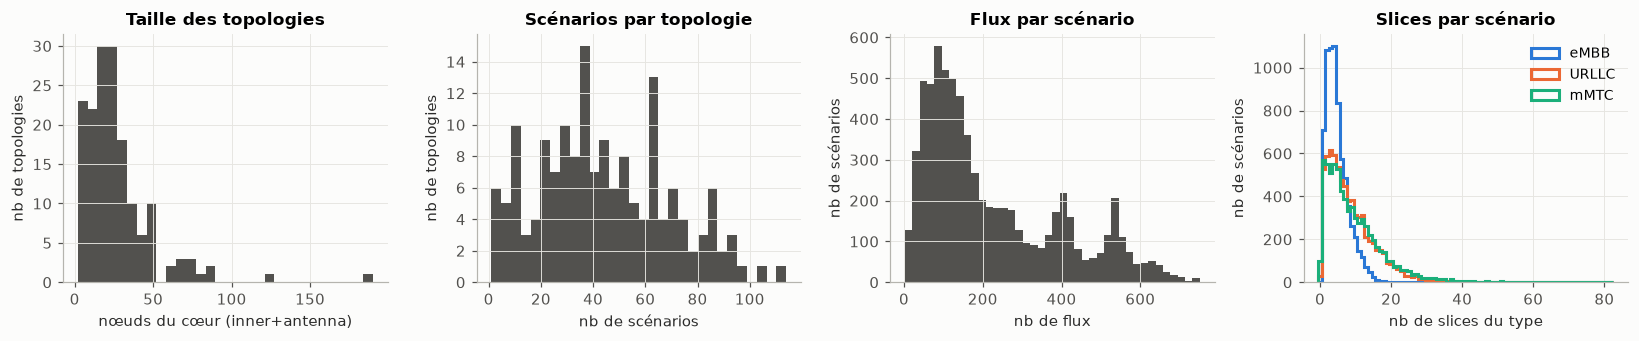

In [4]:
topo = scen.groupby("topology").agg(n_scen=("scenario_id", "size"), n_core_nodes=("n_core_nodes", "first"),
                                    n_core_links=("n_core_links", "first"))
summary["topologies"] = {"n": int(len(topo)), "scen_per_topo_min": int(topo.n_scen.min()),
                         "scen_per_topo_median": float(topo.n_scen.median()), "scen_per_topo_max": int(topo.n_scen.max()),
                         "core_nodes_min": int(topo.n_core_nodes.min()), "core_nodes_max": int(topo.n_core_nodes.max())}
print(summary["topologies"])
fig = fig_inventory(scen); savefig(fig, "L1_01_inventaire"); plt.show()

**Structure d'un scénario.** Chaque graphe contient : un *cœur* issu de Topology Zoo (nœuds `inner`),
des nœuds `antenna` (points d'accès radio), un nœud feuille `origin_*` par source de trafic accroché à une antenne,
et des nœuds `destination_*` par type de slice. Le grand nombre de nœuds (`n_nodes`) vient donc surtout des
sources mMTC (une par capteur), pas de la taille du cœur.

In [5]:
types = raw["links"].groupby(["src_type", "dst_type"]).size().sort_values(ascending=False).head(12)
types

src_type           dst_type         
antenna            origin_mmtc          1185207
origin_mmtc        antenna              1185207
antenna            origin_urllc          325456
origin_urllc       antenna               325456
inner              inner                 169200
origin_embb        antenna                66006
antenna            origin_embb            66006
                   inner                  33925
inner              antenna                33925
destination_mmtc   destination_mmtc       14254
destination_urllc  destination_urllc      14254
destination_embb   destination_embb       14254
dtype: int64

## 2. Qualité des données : types, manquants, doublons, valeurs impossibles

In [6]:
qr = quality_report(raw)
qr.to_csv(RESULTS_DIR / "quality_report.csv", index=False)
print("Colonnes avec valeurs manquantes :")
print(qr[qr.n_missing > 0][["table", "column", "n_missing", "n_rows"]].to_string(index=False))
print("\nClés dupliquées par table :", qr.groupby("table").n_duplicate_keys_in_table.first().to_dict())

Colonnes avec valeurs manquantes :
table            column  n_missing  n_rows
links meas_avg_pkt_size    1854824 3538248

Clés dupliquées par table : {'flow_links': 0, 'flows': 0, 'links': 0, 'scenarios': 0}


Les seules valeurs manquantes attendues sont `meas_*` (statistiques mesurées) sur les liens que le simulateur
ne rapporte pas, et `exp_max_factor` si un flux n'est pas poissonien. Ce sont des sorties ou des constantes, pas des entrées.

In [7]:
iv = impossible_values(f)
summary["impossible_values"] = iv
iv

{'delay_sentinel_-1 (no packet delivered)': 9,
 'delay_negative_other': 0,
 'jitter_negative_other': 0,
 'loss_gt_1': 0,
 'loss_negative': 0,
 'pkts_gen_zero': 0,
 'rate_bps_nonpositive': 0,
 'nan_in_targets': 0,
 'percentiles_not_sorted': 0}

In [8]:
const = {c: f[c].unique().tolist()[:5] for c in ["time_dist", "size_dist", "exp_max_factor"]}
const["max_avg_lambda"] = scen.max_avg_lambda.unique().tolist()[:5]
const["sched_policy"] = raw["links"].sched_policy.unique().tolist()
const["queue_size_pkts"] = sorted(hops.queue_size_pkts.unique().tolist())[:10]
const["rate_bps_by_slice"] = f.groupby("slice_type").rate_bps.unique().apply(lambda v: sorted(v.tolist())[:5]).to_dict()
summary["constants"] = {k: [str(x) for x in v] if isinstance(v, list) else {kk: [str(x) for x in vv] for kk, vv in v.items()} for k, v in const.items()}
const

{'time_dist': [0],
 'size_dist': [2],
 'exp_max_factor': [10.0],
 'max_avg_lambda': [18000000.0],
 'sched_policy': ['WFQ', 'FIFO'],
 'queue_size_pkts': [32],
 'rate_bps_by_slice': {'URLLC': [3498560.0],
  'eMBB': [22500000.0],
  'mMTC': [250000.0]}}

**Vérification du débit réel (JOURNAL D0.3).** Le débit offert est calculé depuis les paramètres du générateur
(`AvgPktsLambda × taille moyenne`). On le compare au débit généré mesuré par le simulateur.

In [9]:
ratio = f.avg_bw_kbps * 1000 / f.rate_bps
nominal_ratio = (f.rate_bps / f.nominal_bw).groupby(f.slice_type).median()
summary["rate_check"] = {"measured_over_rate_median": float(ratio.median()),
                         "measured_over_rate_p01": float(ratio.quantile(0.01)),
                         "measured_over_rate_p99": float(ratio.quantile(0.99)),
                         "rate_over_nominal_by_slice": nominal_ratio.round(4).to_dict()}
summary["rate_check"]

{'measured_over_rate_median': 1.000045733101619,
 'measured_over_rate_p01': 0.998888,
 'measured_over_rate_p99': 1.001208,
 'rate_over_nominal_by_slice': {'URLLC': 0.9996, 'eMBB': 1.25, 'mMTC': 1.25}}

**Le routage simulé diffère souvent du chemin déclaré dans `slices_K.json` (JOURNAL D1.1).**
Le parseur utilise `routing_K.txt`. Preuve : l'utilisation calculée avec ces chemins reproduit l'utilisation
mesurée par le simulateur.

In [10]:
Lm = links[links.meas_util.notna()]
summary["routing_check"] = {
    "frac_flows_path_equal_slice_file": float(f.path_matches_slice_file.mean()),
    "frac_scenarios_all_paths_equal": float(f.groupby("scenario_id").path_matches_slice_file.all().mean()),
    "corr_min_rho1_vs_meas_util": float(np.corrcoef(np.minimum(Lm.rho_link, 1), Lm.meas_util)[0, 1]),
    "mae_min_rho1_vs_meas_util": float(np.abs(np.minimum(Lm.rho_link, 1) - Lm.meas_util).mean()),
    "frac_used_links_rho_gt_1": float((links.rho_link > 1).mean()),
}
summary["routing_check"]

{'frac_flows_path_equal_slice_file': 0.5824678483562498,
 'frac_scenarios_all_paths_equal': 0.23614424021327346,
 'corr_min_rho1_vs_meas_util': 0.9843813397966225,
 'mae_min_rho1_vs_meas_util': 0.0033782754049826186,
 'frac_used_links_rho_gt_1': 0.020578891592373638}

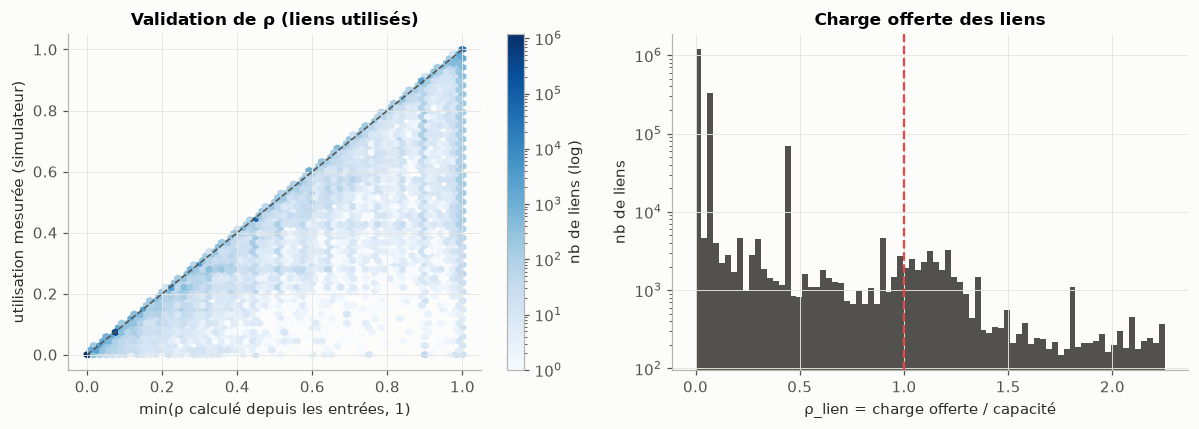

In [11]:
fig = fig_rho_validation(links); savefig(fig, "L1_02_validation_rho"); plt.show()

## 3. Distribution des cibles

In [12]:
d = f[f.has_delay]
tq = d.groupby("slice_type").delay.describe(percentiles=[0.01, 0.1, 0.5, 0.9, 0.99]).round(6)
summary["delay_by_slice"] = tq.to_dict(orient="index")
summary["delay_global"] = {"min": float(d.delay.min()), "median": float(d.delay.median()), "max": float(d.delay.max()),
                           "max_over_min_orders_of_magnitude": float(np.log10(d.delay.max() / d.delay.min())),
                           "skew_raw": float(d.delay.skew()), "skew_log10": float(np.log10(d.delay).skew()),
                           "frac_delay_gt_1s": float((d.delay > 1).mean())}
summary["loss_by_slice"] = f.groupby("slice_type").loss.describe(percentiles=[0.5, 0.9]).round(4).to_dict(orient="index")
print(json.dumps(summary["delay_global"], indent=1))
tq

{
 "min": 1e-05,
 "median": 0.001358,
 "max": 1929.44,
 "max_over_min_orders_of_magnitude": 8.285431277815904,
 "skew_raw": 38.28311384378124,
 "skew_log10": 0.993693540613909,
 "frac_delay_gt_1s": 0.029298643968896275
}


,count,mean,std,min,1%,10%,50%,90%,99%,max
slice_type,,,,,,,,,,
URLLC,325450.0,1.061709,7.084091,0.000016,0.000035,0.000062,0.000519,0.006707,39.332355,178.7280
eMBB,66003.0,16.065962,92.112485,0.000502,0.000599,0.000990,0.013676,0.059156,484.038140,1929.4400
mMTC,1185207.0,0.317808,2.498861,0.000010,0.000012,0.000031,0.001546,0.022337,12.558594,53.3811


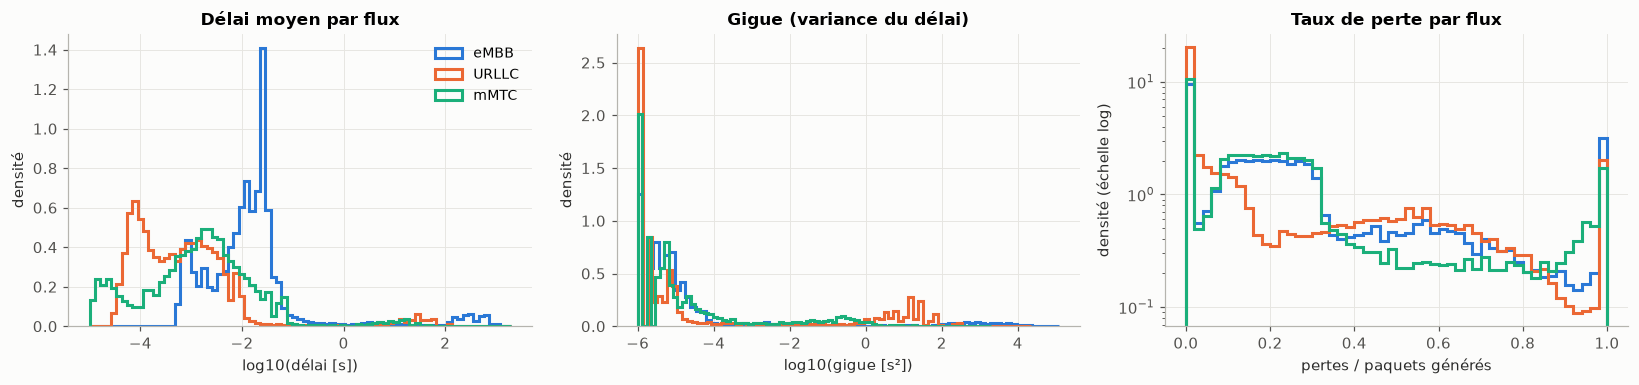

In [13]:
fig = fig_targets(f); savefig(fig, "L1_03_distributions_cibles"); plt.show()

## 4. Délai en fonction des entrées

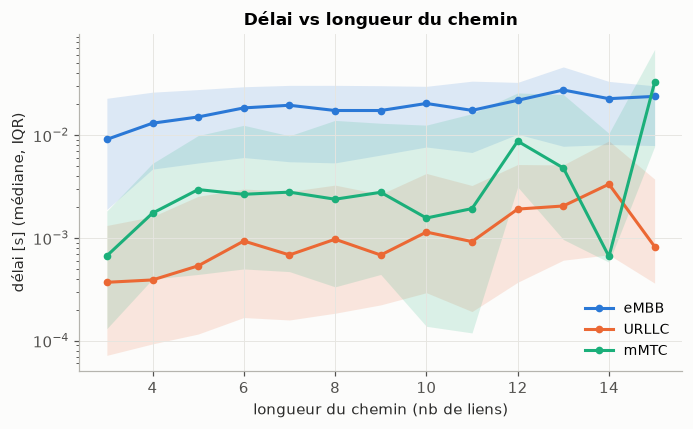

In [14]:
fig = fig_delay_vs(f, "path_len", np.arange(0.5, 16.5, 1), "longueur du chemin (nb de liens)",
                   "Délai vs longueur du chemin"); savefig(fig, "L1_04_delai_vs_longueur"); plt.show()

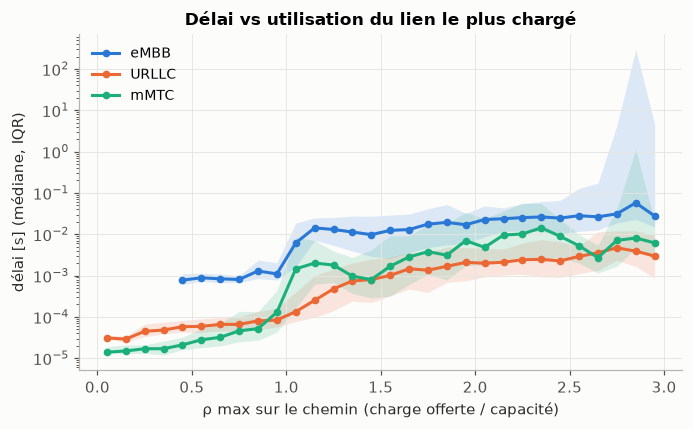

In [15]:
fig = fig_delay_vs(f, "rho_link_max", np.linspace(0, 3, 31), "ρ max sur le chemin (charge offerte / capacité)",
                   "Délai vs utilisation du lien le plus chargé"); savefig(fig, "L1_05_delai_vs_rho"); plt.show()

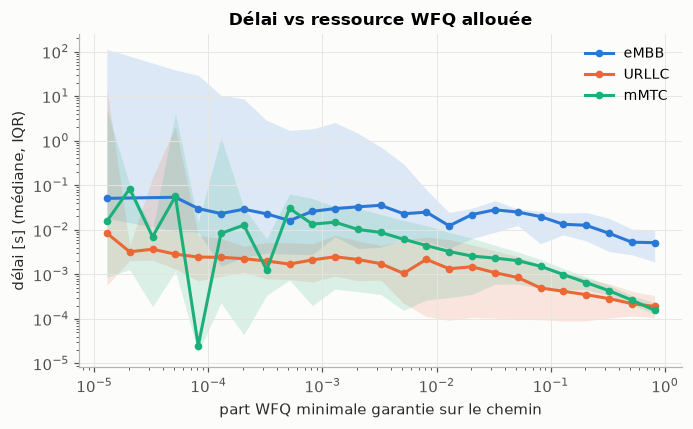

In [16]:
fig = fig_delay_vs(f, "wfq_share_min", np.logspace(-5, 0, 26), "part WFQ minimale garantie sur le chemin",
                   "Délai vs ressource WFQ allouée", logx=True); savefig(fig, "L1_06_delai_vs_wfq"); plt.show()

**Flux « affamés ».** Les délais supérieurs à la seconde correspondent à des flux dont la file WFQ, sur au moins
un port, a un poids quasi nul (la slice n'a pas de réservation sur ce port car le routage simulé s'écarte du chemin
prévu par l'admission). Vérification :

In [17]:
starv = pd.crosstab(f.wfq_share_min < 1e-3, pd.cut(f.delay, [-2, 0, 0.01, 0.1, 1, 1e3],
                                                   labels=["aucun paquet", "<10 ms", "10-100 ms", "0,1-1 s", ">1 s"]))
starv.index = ["part min ≥ 1e-3", "part min < 1e-3"]
summary["starvation_crosstab"] = starv.to_dict()
starv

delay,aucun paquet,<10 ms,10-100 ms,"0,1-1 s",>1 s
part min ≥ 1e-3,0,1144567,158080,1157,435
part min < 1e-3,9,166402,52269,7991,45733


Une part quasi nulle ne suffit pas : WFQ est *conservatif* (il redistribue la capacité inutilisée par les autres
files). Une file de poids ~0 n'est donc affamée que si le lien est **aussi** saturé. On croise les deux conditions
au niveau du saut :

In [18]:
hh = hops[["scenario_id", "flow_id", "wfq_share", "rho_link"]].copy()
hh["part_quasi_nulle"] = hh.wfq_share < 1e-3
hh["part_quasi_nulle_ET_lien_sature"] = hh.part_quasi_nulle & (hh.rho_link >= 1)
anyhop = hh.groupby(["scenario_id", "flow_id"])[["part_quasi_nulle", "part_quasi_nulle_ET_lien_sature"]].any().reset_index()
ff = f[["scenario_id", "flow_id", "delay"]].merge(anyhop)
starv2 = pd.crosstab([ff.part_quasi_nulle, ff.part_quasi_nulle_ET_lien_sature],
                     pd.cut(ff.delay, [-2, 0, 0.01, 0.1, 1, 1e4], labels=["aucun paquet", "<10 ms", "10-100 ms", "0,1-1 s", ">1 s"]))
summary["starvation_x_saturation"] = {f"part<1e-3={a}, part<1e-3 & rho>=1={b}": row.to_dict() for (a, b), row in starv2.iterrows()}
del hh, anyhop, ff
starv2

delay                                             aucun paquet   <10 ms  10-100 ms  0,1-1 s   >1 s
part_quasi_nulle part_quasi_nulle_ET_lien_sature                                                  
False            False                                       0  1144567     158080     1157    435
True             False                                       0    89244      14898      235     15
                 True                                        9    77158      37371     7756  45744

## 5. Corrélations

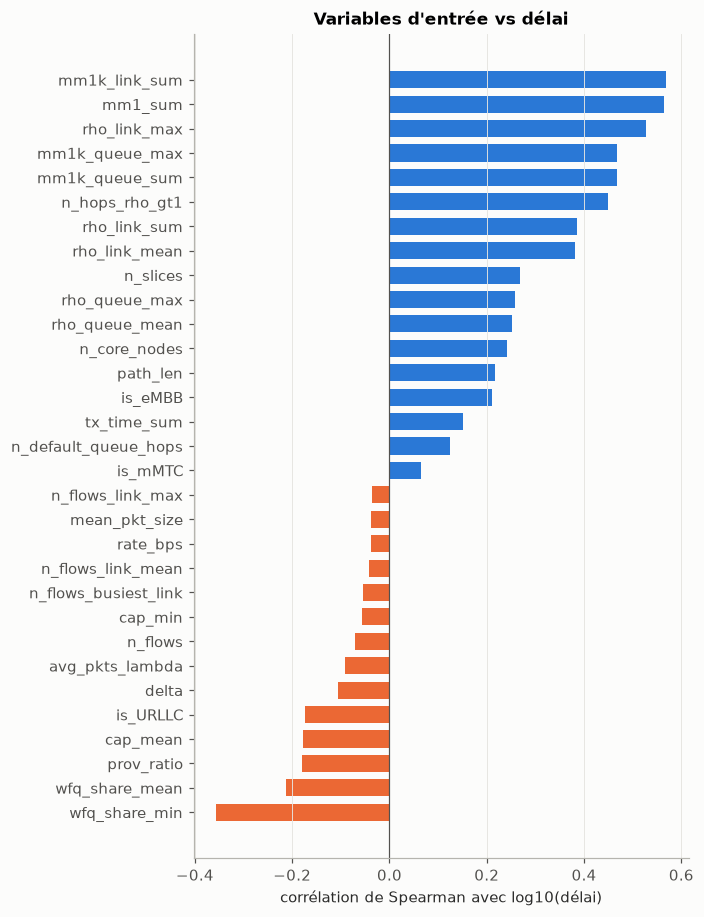

In [19]:
fig, corr = fig_correlations(f, ALL_FEATURES); savefig(fig, "L1_07_correlations_cible"); plt.show()
summary["spearman_with_log_delay"] = corr.round(3).to_dict()

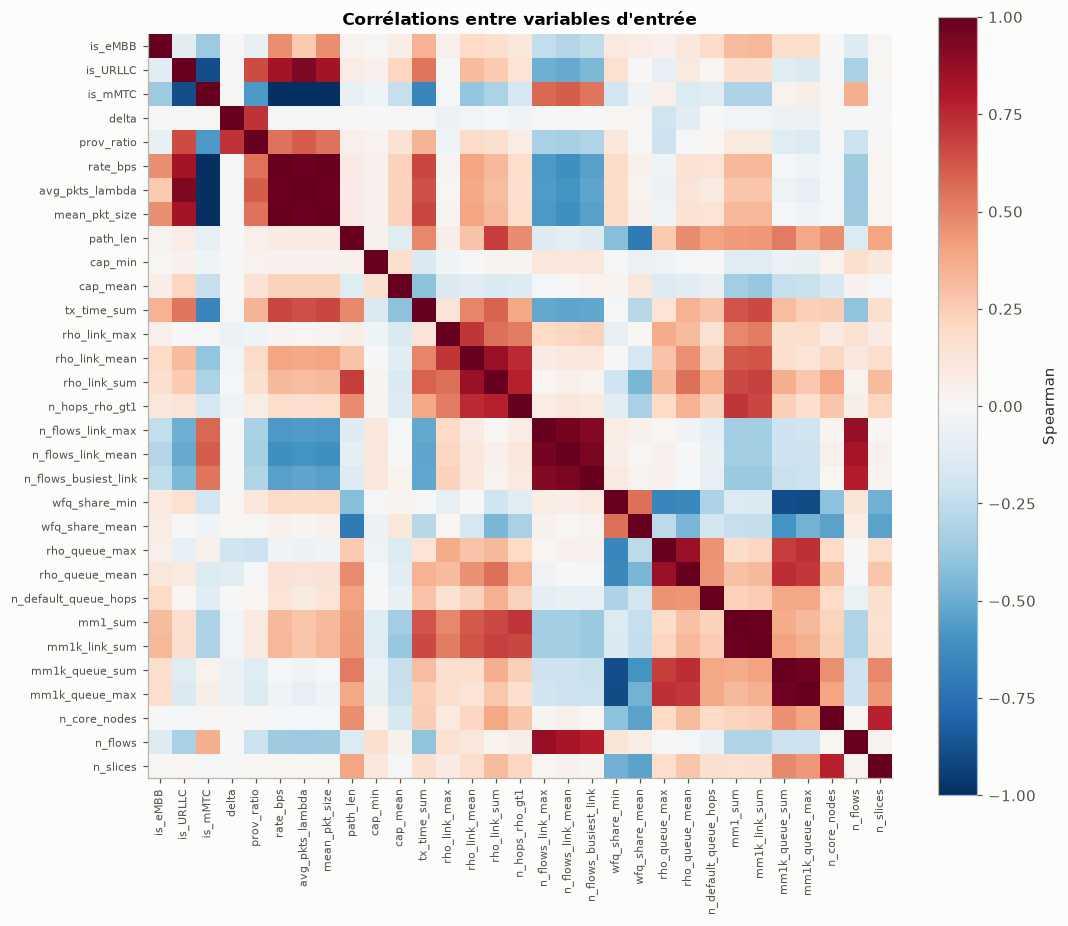

In [20]:
fig = fig_corr_matrix(f.sample(min(len(f), 200_000), random_state=0), ALL_FEATURES)
savefig(fig, "L1_08_correlations_entrees"); plt.show()

## 6. Dictionnaire des variables (livrable L1)

In [21]:
vt = save_variables_table()
vt

,variable,table,signification,type,rôle potentiel,justification
0,scenario_id,flows,Numéro du scénario (graph_K / routing_K / slic...,entier,identifiant,Unité de découpage train/val/test (split group...
1,flow_id,flows,Index du flux dans son scénario,entier,identifiant,"Clé technique, aucune signification physique."
2,topology,scenarios,Nom de la topologie Topology Zoo (162 distinctes),catégoriel,identifiant,Sert au split « topologie inédite » ; l'utilis...
3,"src, dst, antenna",flows,"Nœuds origine, destination et antenne du flux",entier,identifiant,Les numéros de nœuds n'ont pas de sens d'un gr...
4,tar_file,scenarios,Archive d'origine,texte,identifiant,Traçabilité uniquement.
5,slice_type,flows,"Type de slice : eMBB, URLLC ou mMTC",catégoriel (3),entrée,"Détermine taille de paquets, débit et file WFQ..."
6,slice_num,flows,Numéro de slice dans le scénario,entier,identifiant,"Identifiant local, pas d'ordre physique."
7,delta,flows,Facteur de provisionnement de la slice (module...,"réel [0,1]",entrée,"C'est la décision d'allocation : δ<0,5 = sous-..."
8,prov_ratio,flows (dérivée),"Réservation / débit réel offert = (0,85+0,3δ)·...",réel,entrée,Mesure directe du sur/sous-provisionnement par...
9,nominal_bw,flows,Débit déclaré dans le fichier slices (bits/s),réel,à exclure,Sous-estime le débit réel de 25 % pour eMBB/mM...


In [22]:
with open(RESULTS_DIR / "eda_summary.json", "w", encoding="utf-8") as fh:
    json.dump(summary, fh, indent=1, ensure_ascii=False, default=str)
print("écrit : results/eda_summary.json")

écrit : results/eda_summary.json


## 7. Ce qu'il faut retenir (chiffres : `results/eda_summary.json`)

1. **Volume.** 7 127 scénarios valides (773 écartés car la simulation n'a pas atteint l'état `OK`), 162 topologies,
   1,58 M flux, 7,4 M sauts flux→lien. Assez de topologies (41 scénarios par topologie en médiane) pour un test
   sur **topologies inédites**.
2. **Déséquilibre.** 75 % des flux sont mMTC, 21 % URLLC, 4 % eMBB → les métriques seront toujours rapportées
   **par type de slice**, sinon mMTC domine tout.
3. **Cible très asymétrique.** Le délai couvre 8 ordres de grandeur (1e-5 s à ~1 900 s), asymétrie 38 en brut contre
   0,99 en log10 → on prédit **log10(délai)**.
4. **Le profil de trafic est constant par type de slice** (débit, lois, file de 32 paquets) : la variabilité du délai
   vient de la **topologie, du routage, de la compétition entre flux et de l'allocation WFQ**.
5. **ρ calculé depuis les entrées est fiable** (corrélation 0,984 avec l'utilisation mesurée) et le délai montre un
   **coude net à ρ ≈ 1** (figure L1_05) : base du seuil d'événement en L4.
6. **Flux affamés.** ~2,9 % des flux ont un délai > 1 s ; presque tous ont une file WFQ de poids quasi nul **sur un lien
   saturé**. Mais beaucoup de flux dans la même situation restent rapides : aucune règle simple ne sépare les deux,
   il faut un modèle qui voit avec qui chaque file est en compétition → argument pour le GNN.